In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pylab as pl

In [3]:
df=pd.read_csv("student_performance1000.csv")
df.head()

,hours_studied,attendance_percent,previous_score,sleep_hours,extracurricular,final_score,passed
0,3.7,43.1,41.0,4.2,No,69.3,0
1,9.5,71.9,48.1,3.2,Yes,100.0,1
2,7.3,72.4,41.5,4.1,Yes,97.6,1
3,6.0,78.2,35.8,6.5,Yes,95.7,1
4,1.6,83.6,37.8,5.5,No,70.8,0


In [4]:
X=df[['attendance_percent' , 'previous_score' , 'sleep_hours' ,'extracurricular' , 'passed' ]].values
X[0:5]

array([[43.1, 41.0, 4.2, 'No', 0],
       [71.9, 48.1, 3.2, 'Yes', 1],
       [72.4, 41.5, 4.1, 'Yes', 1],
       [78.2, 35.8, 6.5, 'Yes', 1],
       [83.6, 37.8, 5.5, 'No', 0]], dtype=object)

In [5]:
y=df["final_score"]
y[0:5]

0     69.3
1    100.0
2     97.6
3     95.7
4     70.8
Name: final_score, dtype: float64

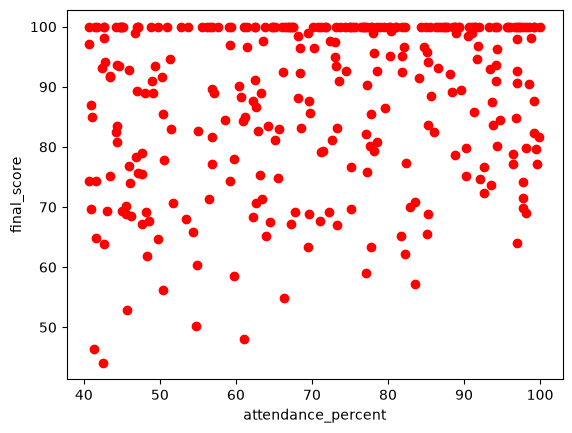

In [6]:
plt.scatter(df.attendance_percent , df.final_score , color='red')
plt.xlabel("attendance_percent")
plt.ylabel("final_score")
plt.show()

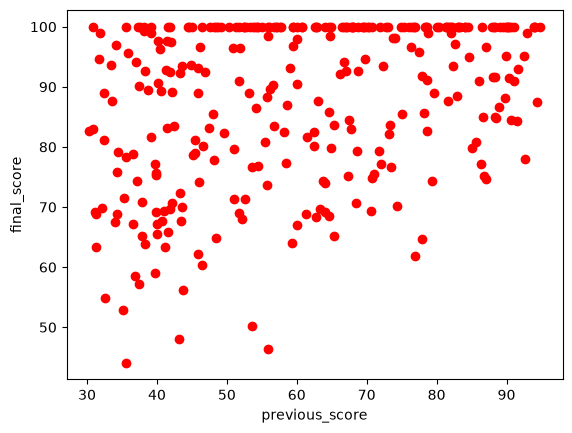

In [7]:
plt.scatter(df.previous_score , df.final_score , color='red')
plt.xlabel("previous_score")
plt.ylabel("final_score")
plt.show()

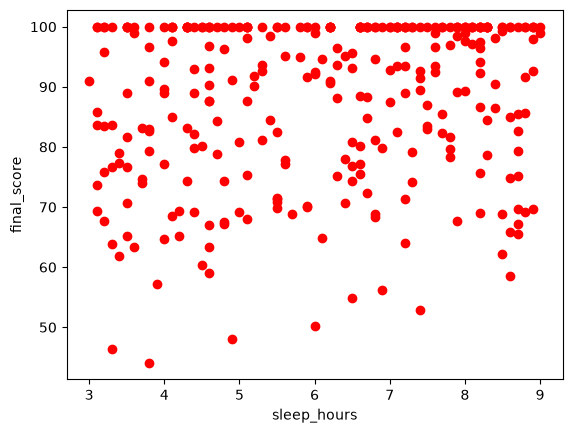

In [8]:
plt.scatter(df.sleep_hours , df.final_score , color='red')
plt.xlabel("sleep_hours")
plt.ylabel("final_score")
plt.show()

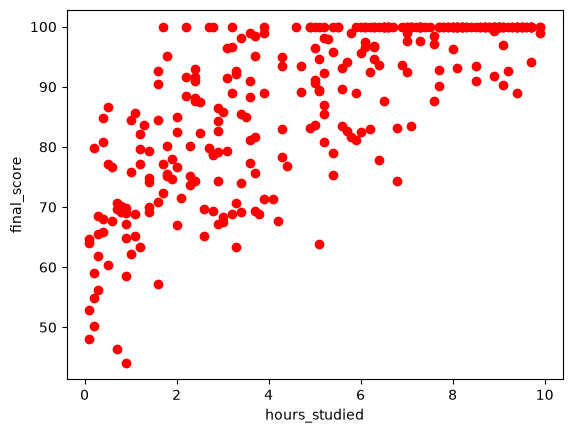

In [9]:
plt.scatter(df.hours_studied , df.final_score , color='red')
plt.xlabel("hours_studied")
plt.ylabel("final_score")
plt.show()

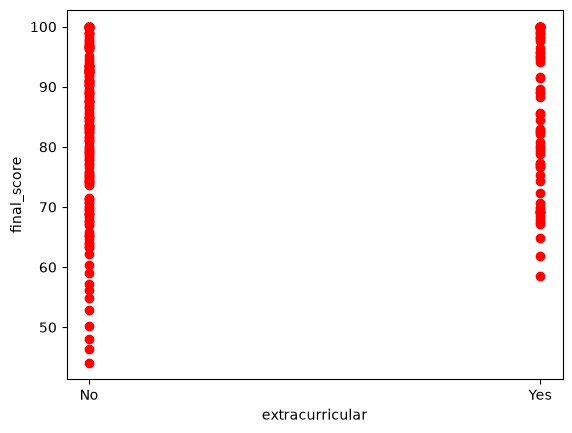

In [10]:
plt.scatter(df.extracurricular , df.final_score , color='red')
plt.xlabel("extracurricular")
plt.ylabel("final_score")
plt.show()

In [11]:
msk = np.random.rand(len(X))  < 0.8
train = df [msk]
test = df [~msk]

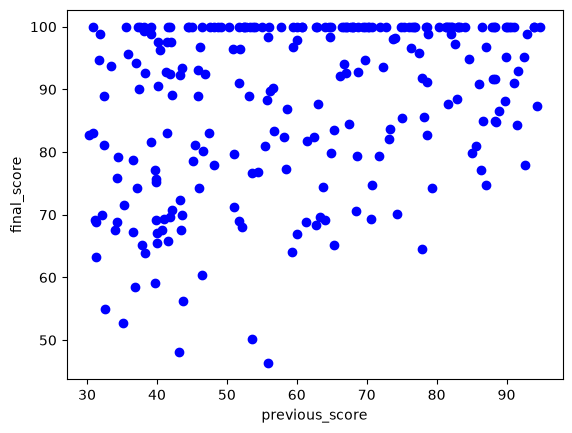

In [12]:
plt.scatter(train.previous_score , train.final_score ,  color='blue')
plt.xlabel("previous_score")
plt.ylabel("final_score")
plt.show()

In [13]:
from sklearn import linear_model
A = linear_model.LinearRegression()
X= np.asanyarray(train[['attendance_percent' , 'previous_score' , 'sleep_hours']])
y=np.asanyarray(train[['final_score']])
A.fit(X , y)
print ('Coefficients: ', A.coef_)
print('intercept:' , A.intercept_)


Coefficients:  [[0.13637406 0.24533837 1.07129361]]
intercept: [56.82835718]


In [14]:
y_hat = A.predict(test[['attendance_percent' , 'previous_score' , 'sleep_hours']])
x = np.asanyarray(test[['attendance_percent' , 'previous_score' , 'sleep_hours']])
y = np.asanyarray(test[['final_score']])
print("Residual sum of squares: %.2f"
      % np.mean((y_hat - y) ** 2))

# Explained variance score: 1 is perfect prediction
print('Variance score: %.2f' % A.score(x, y))

Residual sum of squares: 155.03
Variance score: 0.19


c:\Users\island\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [16]:

print("Mean absolute error: %.2f" % np.mean(np.absolute(y_hat - y)))
print("Residual sum of squares (MSE): %.2f" % np.mean((y_hat - y) ** 2))


Mean absolute error: 10.27
Residual sum of squares (MSE): 155.03
